In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls "/content/drive/MyDrive"

 carpeta_salida
'Colab Notebooks'
'con respecto a todo mi documento , me puedes hace....gsheet'
'Copia de 2- C LARO DE LUNA DEBUSY.mp3'
'Documento sin título.gdoc'
'expo intento 2.mp4'
 garbage-dataset.zip
'Gemini Gems'
 INFRA
 INSO
'LINE DE TRACTORES FERREYROS PARA JARDIN Y USO DOMESTICO CONTINUA.....pdf'
'LINE DE TRACTORES FERREYROS PARA JARDIN Y USO DOMESTICO.gdoc'
'LINE DE TRACTORES FERREYROS PARA JARDIN Y USO DOMESTICO.pdf'
 mejor_modelo_residuos.h5
 modelo_residuos_completo.h5
 modelo_residuos.h5
 modelo_tfjs
'PPT GENERAL DE PROBLEMAS DE OPTMIZACION.pptx'
 proyecto_upao_residuos


In [ ]:
!cp "/content/drive/MyDrive/garbage-dataset.zip" .

In [ ]:
!ls -lh

total 745M
drwx------ 5 root root 4.0K May 21 13:50 drive
-rw------- 1 root root 745M May 21 13:51 garbage-dataset.zip
drwxr-xr-x 1 root root 4.0K May 15 13:25 sample_data


In [ ]:
!unzip -q garbage-dataset.zip -d garbage

In [ ]:
!ls

drive  garbage	garbage-dataset.zip  sample_data


In [ ]:
!ls garbage

garbage-dataset


In [ ]:
!ls garbage/garbage-dataset

battery     cardboard  glass  paper    shoes
biological  clothes    metal  plastic  trash


In [ ]:
!rm -r /content/garbage/garbage-dataset/clothes
!rm -r /content/garbage/garbage-dataset/shoes

In [ ]:
!ls garbage/garbage-dataset

battery  biological  cardboard	glass  metal  paper  plastic  trash


Dataset encontrado en: garbage/garbage-dataset

Categorías encontradas (8):
  1. battery
  2. biological
  3. cardboard
  4. glass
  5. metal
  6. paper
  7. plastic
  8. trash

📊 ESTADÍSTICAS DEL DATASET:
Total de categorías: 8
Total de imágenes: 12458

Imágenes por categoría:
  battery: 944 imágenes (7.6%)
  biological: 997 imágenes (8.0%)
  cardboard: 1825 imágenes (14.6%)
  glass: 3061 imágenes (24.6%)
  metal: 1020 imágenes (8.2%)
  paper: 1680 imágenes (13.5%)
  plastic: 1984 imágenes (15.9%)
  trash: 947 imágenes (7.6%)


/tmp/ipykernel_1301/1355951233.py:76: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


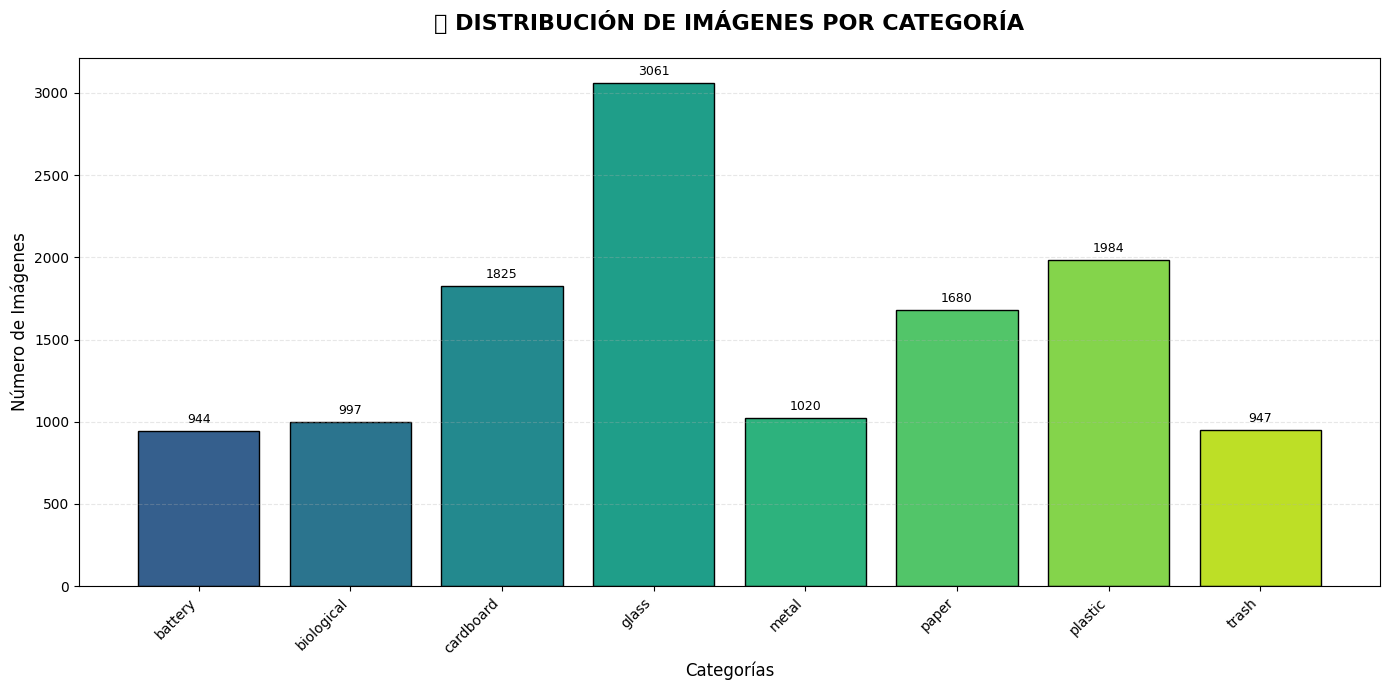

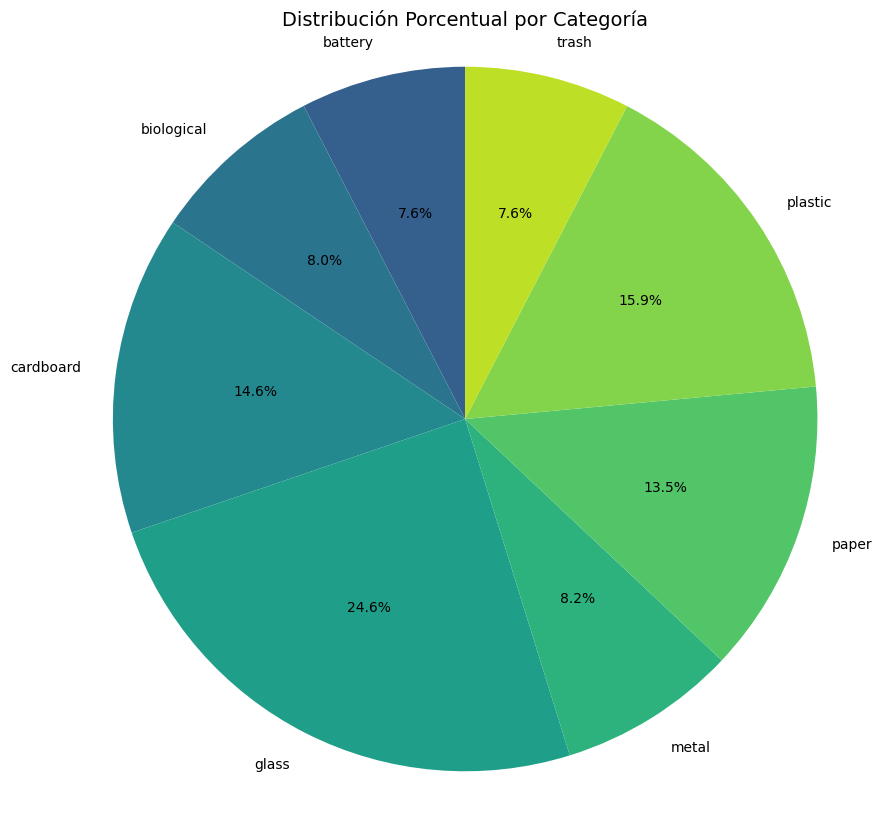


📈 RESUMEN:
Categoría con MÁS imágenes: glass (3061 imágenes)
Categoría con MENOS imágenes: battery (944 imágenes)
Ratio máximo/mínimo: 3.2x

🔍 Muestra de estructura de archivos (primera categoría):
Carpeta: 'battery' → Primeros archivos: ['battery_730.jpg', 'battery_554.jpg', 'battery_648.jpg']


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

# 1. Definir la ruta de tu dataset (según lo que mencionas)
dataset_path = 'garbage/garbage-dataset'

# 2. Verificar que la ruta existe
if not os.path.exists(dataset_path):
    print(f"Error: La ruta '{dataset_path}' no existe.")
    print("Listando directorio actual:")
    !ls -la
else:
    print(f"Dataset encontrado en: {dataset_path}")

    # 3. Listar las carpetas/clases disponibles
    categorias = [c for c in os.listdir(dataset_path)
                  if os.path.isdir(os.path.join(dataset_path, c))]

    print(f"\nCategorías encontradas ({len(categorias)}):")
    for i, cat in enumerate(sorted(categorias)):
        print(f"  {i+1}. {cat}")

    # 4. Contar imágenes por categoría
    categorias_ordenadas = []
    cantidades = []
    total_imagenes = 0

    for categoria in sorted(categorias):
        categoria_path = os.path.join(dataset_path, categoria)
        # Contar solo archivos de imagen
        imagenes = [f for f in os.listdir(categoria_path)
                   if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif', '.webp', '.tiff'))]

        num_imagenes = len(imagenes)
        if num_imagenes > 0:
            categorias_ordenadas.append(categoria)
            cantidades.append(num_imagenes)
            total_imagenes += num_imagenes

    # 5. Mostrar estadísticas
    print(f"\n📊 ESTADÍSTICAS DEL DATASET:")
    print(f"Total de categorías: {len(categorias_ordenadas)}")
    print(f"Total de imágenes: {total_imagenes}")
    print("\nImágenes por categoría:")
    for cat, cant in zip(categorias_ordenadas, cantidades):
        porcentaje = (cant / total_imagenes) * 100
        print(f"  {cat}: {cant} imágenes ({porcentaje:.1f}%)")

    # 6. Crear el gráfico de barras
    plt.figure(figsize=(14, 7))

    # Crear barras con colores según cantidad
    colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(categorias_ordenadas)))
    bars = plt.bar(categorias_ordenadas, cantidades, color=colors, edgecolor='black')

    # Personalizar el gráfico
    plt.title('📊 DISTRIBUCIÓN DE IMÁGENES POR CATEGORÍA', fontsize=16, fontweight='bold', pad=20)
    plt.xlabel('Categorías', fontsize=12)
    plt.ylabel('Número de Imágenes', fontsize=12)

    # Rotar etiquetas si hay muchas categorías
    if len(categorias_ordenadas) > 5:
        plt.xticks(rotation=45, ha='right')

    # Añadir valores encima de las barras
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + max(cantidades)*0.01,
                f'{int(height)}', ha='center', va='bottom', fontsize=9)

    # Añadir grid
    plt.grid(axis='y', alpha=0.3, linestyle='--')

    # Ajustar layout
    plt.tight_layout()

    # 7. Mostrar el gráfico
    plt.show()

    # 8. Opcional: Gráfico de pastel
    if len(categorias_ordenadas) <= 15:  # Solo si no hay demasiadas categorías
        plt.figure(figsize=(10, 10))
        plt.pie(cantidades, labels=categorias_ordenadas, autopct='%1.1f%%',
                startangle=90, colors=colors)
        plt.title('Distribución Porcentual por Categoría', fontsize=14)
        plt.axis('equal')
        plt.show()

    # 9. Información adicional
    print("\n📈 RESUMEN:")
    print(f"Categoría con MÁS imágenes: {categorias_ordenadas[np.argmax(cantidades)]} ({max(cantidades)} imágenes)")
    print(f"Categoría con MENOS imágenes: {categorias_ordenadas[np.argmin(cantidades)]} ({min(cantidades)} imágenes)")
    print(f"Ratio máximo/mínimo: {max(cantidades)/min(cantidades):.1f}x")

    # 10. Verificar algunas imágenes (opcional)
    print("\n🔍 Muestra de estructura de archivos (primera categoría):")
    primera_categoria = categorias_ordenadas[0]
    ejemplo_path = os.path.join(dataset_path, primera_categoria)
    archivos_ejemplo = [f for f in os.listdir(ejemplo_path)
                       if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:3]
    print(f"Carpeta: '{primera_categoria}' → Primeros archivos: {archivos_ejemplo}")

In [ ]:
class_weight.compute_class_weight(...)

📸 Mostrando 5 imágenes de cada una de las 8 categorías


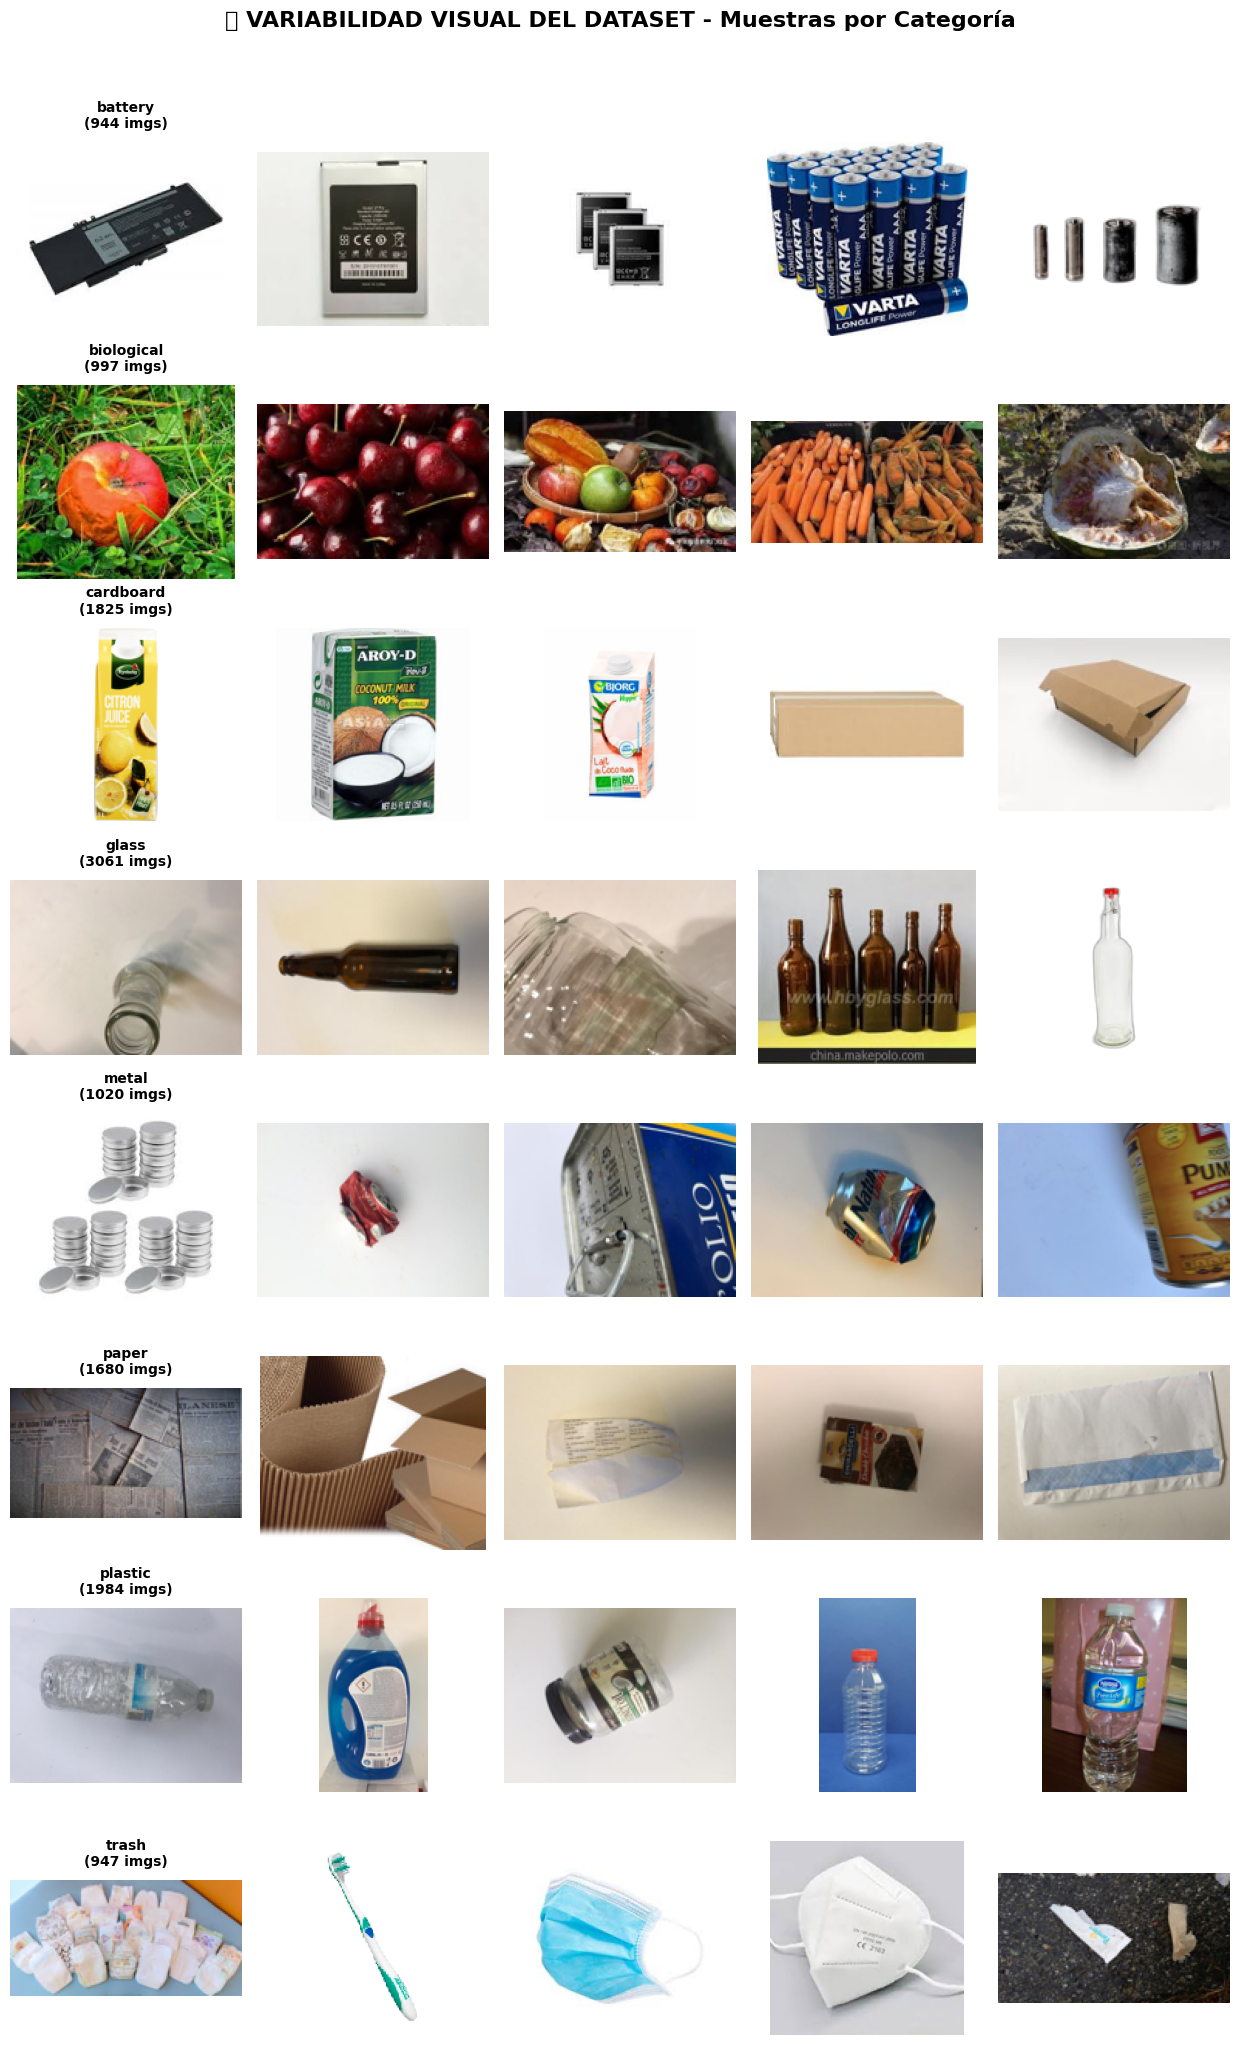


📊 ESTADÍSTICAS DE IMÁGENES:
  battery: Ejemplos de tamaños [(280, 180), (225, 225), (260, 194)]
  biological: Ejemplos de tamaños [(299, 169), (264, 191), (281, 179)]
  cardboard: Ejemplos de tamaños [(474, 355), (512, 384), (245, 206)]
  glass: Ejemplos de tamaños [(474, 355), (225, 225), (272, 185)]
  metal: Ejemplos de tamaños [(512, 384), (512, 384), (225, 225)]


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import random
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# Configuración
dataset_path = 'garbage/garbage-dataset'
muestras_por_clase = 5  # Cambia este valor si quieres más/menos muestras
categorias = sorted([c for c in os.listdir(dataset_path)
                     if os.path.isdir(os.path.join(dataset_path, c))])

print(f"📸 Mostrando {muestras_por_clase} imágenes de cada una de las {len(categorias)} categorías")

# Configurar el grid de visualización
fig, axes = plt.subplots(len(categorias), muestras_por_clase,
                         figsize=(muestras_por_clase * 2.5, len(categorias) * 2.5))

if len(categorias) == 1:
    axes = axes.reshape(1, -1)

for i, categoria in enumerate(categorias):
    categoria_path = os.path.join(dataset_path, categoria)

    # Obtener todas las imágenes de esta categoría
    imagenes = [f for f in os.listdir(categoria_path)
                if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))]

    if len(imagenes) == 0:
        print(f"⚠️ No se encontraron imágenes en: {categoria}")
        continue

    # Seleccionar muestras aleatorias (o menos si no hay suficientes)
    muestras = random.sample(imagenes, min(muestras_por_clase, len(imagenes)))

    for j, img_name in enumerate(muestras):
        try:
            img_path = os.path.join(categoria_path, img_name)
            img = Image.open(img_path)

            # Redimensionar para visualización consistente
            img.thumbnail((150, 150))

            ax = axes[i, j] if len(categorias) > 1 else axes[j]
            ax.imshow(img)
            ax.axis('off')

            # Solo poner título en la primera columna
            if j == 0:
                ax.set_title(f"{categoria}\n({len(imagenes)} imgs)",
                           fontsize=10, fontweight='bold', pad=10)

            # Mostrar info de la imagen en tooltip (hover)
            ax.set_xlabel(f"{img.size[0]}x{img.size[1]}", fontsize=6)

        except Exception as e:
            print(f"Error cargando {img_name}: {e}")
            axes[i, j].axis('off')
            axes[i, j].text(0.5, 0.5, 'Error', ha='center', va='center')

plt.suptitle('🎨 VARIABILIDAD VISUAL DEL DATASET - Muestras por Categoría',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Estadísticas adicionales de las imágenes
print("\n📊 ESTADÍSTICAS DE IMÁGENES:")
for categoria in categorias[:5]:  # Mostrar solo primeras 5 para no saturar
    categoria_path = os.path.join(dataset_path, categoria)
    imagenes = [f for f in os.listdir(categoria_path)
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:10]  # Solo primeras 10

    if imagenes:
        tamaños = []
        for img_name in imagenes[:3]:  # Analizar solo 3 para muestra
            try:
                img_path = os.path.join(categoria_path, img_name)
                with Image.open(img_path) as img:
                    tamaños.append(img.size)
            except:
                pass

        if tamaños:
            print(f"  {categoria}: Ejemplos de tamaños {tamaños[:3]}")

🔍 ANALIZANDO CARACTERÍSTICAS VISUALES DEL DATASET...

📊 ESTADÍSTICAS DE FORMATO:
  JPEG: 72 imágenes
  PNG: 8 imágenes

🎨 MODOS DE COLOR MÁS COMUNES:
  RGB: 72 imágenes
  RGBA: 8 imágenes

📏 TAMAÑOS MÁS COMUNES (TOP 10):
  225x225: 13 imágenes
  512x384: 11 imágenes
  275x183: 4 imágenes
  474x474: 3 imágenes
  259x194: 2 imágenes
  238x212: 2 imágenes
  265x190: 2 imágenes
  474x355: 2 imágenes
  256x197: 1 imágenes
  600x936: 1 imágenes


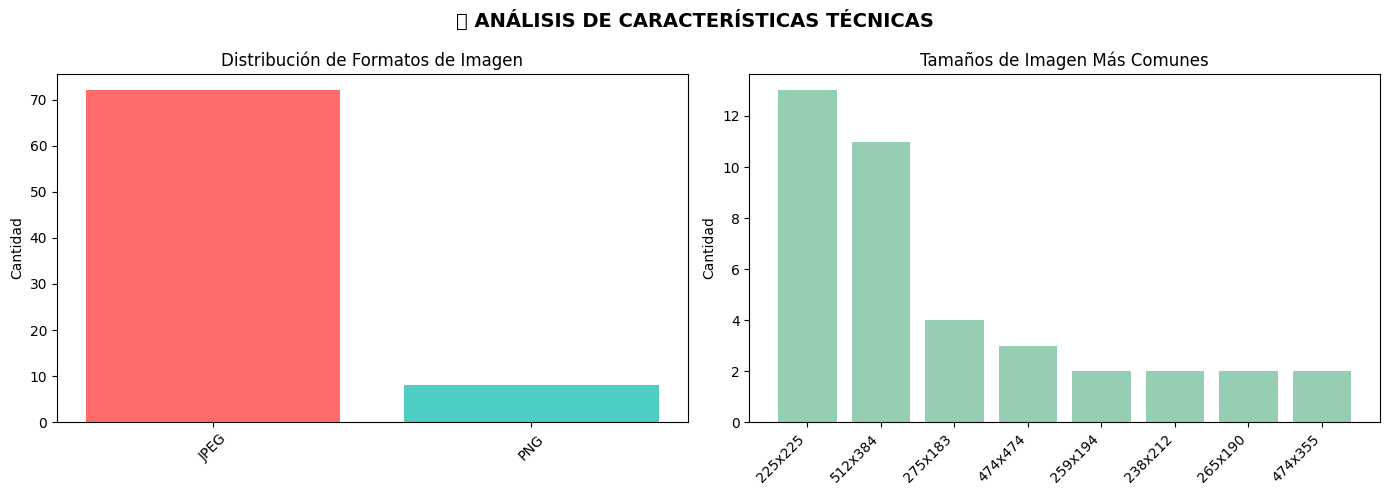

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
from collections import defaultdict

dataset_path = 'garbage/garbage-dataset'

# Análisis de formatos, tamaños y canales
estadisticas = {
    'formatos': defaultdict(int),
    'tamaños': defaultdict(int),
    'canales': defaultdict(int),
    'modos': defaultdict(int)
}

# Analizar una muestra de imágenes
print("🔍 ANALIZANDO CARACTERÍSTICAS VISUALES DEL DATASET...\n")

for categoria in os.listdir(dataset_path)[:10]:  # Analizar solo primeras 10 categorías para velocidad
    categoria_path = os.path.join(dataset_path, categoria)
    if os.path.isdir(categoria_path):
        imagenes = [f for f in os.listdir(categoria_path)
                   if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:10]  # Solo 10 por categoría

        for img_name in imagenes:
            try:
                img_path = os.path.join(categoria_path, img_name)
                with Image.open(img_path) as img:
                    # Formato
                    formato = img.format if img.format else 'DESCONOCIDO'
                    estadisticas['formatos'][formato] += 1

                    # Tamaño (agrupar por rangos)
                    ancho, alto = img.size
                    tamaño_clave = f"{ancho}x{alto}"
                    estadisticas['tamaños'][tamaño_clave] += 1

                    # Canales y modo
                    if hasattr(img, 'mode'):
                        estadisticas['modos'][img.mode] += 1
                    if hasattr(img, 'getbands'):
                        estadisticas['canales'][len(img.getbands())] += 1

            except Exception as e:
                continue

# Mostrar estadísticas
print("📊 ESTADÍSTICAS DE FORMATO:")
for formato, count in sorted(estadisticas['formatos'].items(), key=lambda x: x[1], reverse=True):
    print(f"  {formato}: {count} imágenes")

print("\n🎨 MODOS DE COLOR MÁS COMUNES:")
for modo, count in sorted(estadisticas['modos'].items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"  {modo}: {count} imágenes")

print("\n📏 TAMAÑOS MÁS COMUNES (TOP 10):")
for tamaño, count in sorted(estadisticas['tamaños'].items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {tamaño}: {count} imágenes")

# Gráfico de distribución de tamaños
if estadisticas['tamaños']:
    tamaños_comunes = sorted(estadisticas['tamaños'].items(),
                            key=lambda x: x[1], reverse=True)[:8]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico de formatos
    formatos = list(estadisticas['formatos'].keys())
    counts = list(estadisticas['formatos'].values())
    ax1.bar(formatos, counts, color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
    ax1.set_title('Distribución de Formatos de Imagen')
    ax1.set_ylabel('Cantidad')
    ax1.tick_params(axis='x', rotation=45)

    # Gráfico de tamaños comunes
    etiquetas = [t[0] for t in tamaños_comunes]
    valores = [t[1] for t in tamaños_comunes]
    ax2.bar(range(len(etiquetas)), valores, color='#96CEB4')
    ax2.set_title('Tamaños de Imagen Más Comunes')
    ax2.set_ylabel('Cantidad')
    ax2.set_xticks(range(len(etiquetas)))
    ax2.set_xticklabels(etiquetas, rotation=45, ha='right')

    plt.suptitle('📐 ANÁLISIS DE CARACTERÍSTICAS TÉCNICAS', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
# --- PREPARACION DEL DATASET ---
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import os
import pandas as pd

print("=== SISTEMA DE CLASIFICACION DE RESIDUOS UPAO ===")
print("Configuracion inicial completada")

# Configuracion de GPU para computo distribuido
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print("GPU detectada:", gpus)
    strategy = tf.distribute.MirroredStrategy()
    print("Estrategia distribuida activada - Entrenamiento acelerado")
else:
    print("Usando CPU")
    strategy = tf.distribute.OneDeviceStrategy('/cpu:0')

=== SISTEMA DE CLASIFICACION DE RESIDUOS UPAO ===
Configuracion inicial completada
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Estrategia distribuida activada - Entrenamiento acelerado


In [ ]:
# --- PARAMETROS DEL PROYECTO ---
batch_size = 32
img_size = (224, 224)
dataset_path = 'garbage/garbage-dataset'
num_classes = 8

print("\n=== CONFIGURACION DE PARAMETROS ===")
print(f"Batch size: {batch_size}")
print(f"Tamaño de imagen: {img_size}")
print(f"Ruta del dataset: {dataset_path}")
print(f"Numero de clases: {num_classes}")


=== CONFIGURACION DE PARAMETROS ===
Batch size: 32
Tamaño de imagen: (224, 224)
Ruta del dataset: garbage/garbage-dataset
Numero de clases: 8


In [ ]:
# --- ANALISIS DEL DATASET ---
print("\n=== ANALISIS DEL DATASET ===")
if os.path.exists(dataset_path):
    categorias = sorted(os.listdir(dataset_path))
    print("Categorias de residuos encontradas:")

    distribucion = {}
    for categoria in categorias:
        categoria_path = os.path.join(dataset_path, categoria)
        if os.path.isdir(categoria_path):
            num_imagenes = len(os.listdir(categoria_path))
            distribucion[categoria] = num_imagenes
            print(f"  {categoria}: {num_imagenes} imagenes")

    total_imagenes = sum(distribucion.values())
    print(f"\nTotal de imagenes en el dataset: {total_imagenes}")
else:
    print("Error: Dataset no encontrado")


=== ANALISIS DEL DATASET ===
Categorias de residuos encontradas:
  battery: 944 imagenes
  biological: 997 imagenes
  cardboard: 1825 imagenes
  glass: 3061 imagenes
  metal: 1020 imagenes
  paper: 1680 imagenes
  plastic: 1984 imagenes
  trash: 947 imagenes

Total de imagenes en el dataset: 12458


In [ ]:
# --- PREPROCESAMIENTO Y AUMENTACION DE DATOS ---
print("\n=== PREPROCESAMIENTO DE DATOS ===")

# Configuracion de aumentacion de datos para entrenamiento
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Solo normalizacion para validacion
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

print("Generadores de datos configurados")

# Creacion de generadores de datos
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

print(f"Imagenes de entrenamiento: {train_generator.samples}")
print(f"Imagenes de validacion: {val_generator.samples}")
print(f"Clases identificadas: {list(train_generator.class_indices.keys())}")


=== PREPROCESAMIENTO DE DATOS ===
Generadores de datos configurados
Found 9969 images belonging to 8 classes.
Found 2489 images belonging to 8 classes.
Imagenes de entrenamiento: 9969
Imagenes de validacion: 2489
Clases identificadas: ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [ ]:
# --- BALANCEO DE CLASES ---
print("\n=== BALANCEO DE CLASES ===")

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))

print("Pesos calculados para balancear clases:")
for clase, peso in class_weights_dict.items():
    nombre_clase = list(train_generator.class_indices.keys())[clase]
    print(f"  {nombre_clase}: {peso:.4f}")


=== BALANCEO DE CLASES ===
Pesos calculados para balancear clases:
  battery: 1.6483
  biological: 1.5616
  cardboard: 0.8535
  glass: 0.5088
  metal: 1.5271
  paper: 0.9272
  plastic: 0.7847
  trash: 1.6440


In [ ]:
# --- CONSTRUCCION DEL MODELO CON TRANSFER LEARNING ---
print("\n=== CONSTRUCCION DEL MODELO ===")
print("Usando MobileNetV2 con Transfer Learning")

with strategy.scope():
    # Modelo base pre-entrenado
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        include_top=False,
        weights='imagenet',
        pooling='avg'
    )

    # Congelar capas base inicialmente
    base_model.trainable = False
    print("Modelo base MobileNetV2 cargado y congelado")

    # Capas personalizadas para clasificacion de residuos
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(train_generator.num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    # Compilacion del modelo
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'precision', 'recall']
    )

print("Arquitectura del modelo:")
model.summary()


=== CONSTRUCCION DEL MODELO ===
Usando MobileNetV2 con Transfer Learning
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Modelo base MobileNetV2 cargado y congelado
Arquitectura del modelo:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# --- CONFIGURACION DE ENTRENAMIENTO ---
print("\n=== CONFIGURACION DE ENTRENAMIENTO ===")

# Crear directorio para modelos
os.makedirs('modelos_upa', exist_ok=True)

# Callbacks para optimizacion del entrenamiento
callbacks = [
    ModelCheckpoint(
        'modelos_upa/mejor_modelo_residuos.h5',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configurados: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau")


=== CONFIGURACION DE ENTRENAMIENTO ===
Callbacks configurados: ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [ ]:
# --- ENTRENAMIENTO DEL MODELO ---
print("\n=== INICIANDO ENTRENAMIENTO ===")
print("Proceso de entrenamiento con validacion en tiempo real")

epochs = 40

history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator,
    callbacks=callbacks,
    class_weight=class_weights_dict,
    verbose=1
)

print("Entrenamiento completado exitosamente")


=== INICIANDO ENTRENAMIENTO ===
Proceso de entrenamiento con validacion en tiempo real


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.6104 - loss: 1.0840 - precision: 0.7425 - recall: 0.4857
Epoch 1: val_accuracy improved from -inf to 0.85777, saving model to modelos_upa/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 178s 546ms/step - accuracy: 0.6108 - loss: 1.0830 - precision: 0.7427 - recall: 0.4861 - val_accuracy: 0.8578 - val_loss: 0.4159 - val_precision: 0.8943 - val_recall: 0.8256 - learning_rate: 0.0010
Epoch 2/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 529ms/step - accuracy: 0.8062 - loss: 0.5182 - precision: 0.8565 - recall: 0.7659
Epoch 2: val_accuracy improved from 0.85777 to 0.86661, saving model to modelos_upa/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 174s 557ms/step - accuracy: 0.8062 - loss: 0.5182 - precision: 0.8565 - recall: 0.7659 - val_accuracy: 0.8666 - val_loss: 0.3713 - val_precision: 0.9017 - val_recall: 0.8441 - learning_rate: 0.0010
Epoch 3/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 517ms/step - accuracy: 0.8315 - loss: 0.4423 - precision: 0.8716 - recall: 0.7958
Epoch 3: val_accuracy improved from 0.86661 to 0.87746, saving model to modelos_upa/mejor_modelo_residuos.h5


312/312 ━━━━━━━━━━━━━━━━━━━━ 171s 548ms/step - accuracy: 0.8315 - loss: 0.4423 - precision: 0.8716 - recall: 0.7958 - val_accuracy: 0.8775 - val_loss: 0.3596 - val_precision: 0.9033 - val_recall: 0.8481 - learning_rate: 0.0010
Epoch 4/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 594ms/step - accuracy: 0.8442 - loss: 0.4024 - precision: 0.8795 - recall: 0.8143
Epoch 4: val_accuracy improved from 0.87746 to 0.88951, saving model to modelos_upa/mejor_modelo_residuos.h5


... (4 outputs left out)

312/312 ━━━━━━━━━━━━━━━━━━━━ 169s 539ms/step - accuracy: 0.8853 - loss: 0.2931 - precision: 0.9100 - recall: 0.8646 - val_accuracy: 0.9100 - val_loss: 0.2832 - val_precision: 0.9231 - val_recall: 0.8967 - learning_rate: 0.0010
Epoch 14/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.8901 - loss: 0.2676 - precision: 0.9149 - recall: 0.8730
Epoch 14: val_accuracy did not improve from 0.91000
312/312 ━━━━━━━━━━━━━━━━━━━━ 167s 535ms/step - accuracy: 0.8901 - loss: 0.2676 - precision: 0.9149 - recall: 0.8730 - val_accuracy: 0.9040 - val_loss: 0.2885 - val_precision: 0.9202 - val_recall: 0.8891 - learning_rate: 0.0010
Epoch 15/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9014 - loss: 0.2500 - precision: 0.9191 - recall: 0.8856
Epoch 15: val_accuracy did not improve from 0.91000
312/312 ━━━━━━━━━━━━━━━━━━━━ 167s 535ms/step - accuracy: 0.9013 - loss: 0.2501 - precision: 0.9191 - recall: 0.8855 - val_accuracy: 0.8907 - val_loss: 0.3167 - val_precision: 0.9127 - val_re

312/312 ━━━━━━━━━━━━━━━━━━━━ 171s 547ms/step - accuracy: 0.9082 - loss: 0.2130 - precision: 0.9257 - recall: 0.8943 - val_accuracy: 0.9124 - val_loss: 0.2794 - val_precision: 0.9244 - val_recall: 0.8996 - learning_rate: 5.0000e-04
Epoch 22/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.9136 - loss: 0.2131 - precision: 0.9302 - recall: 0.9002
Epoch 22: val_accuracy did not improve from 0.91241
312/312 ━━━━━━━━━━━━━━━━━━━━ 169s 542ms/step - accuracy: 0.9136 - loss: 0.2132 - precision: 0.9302 - recall: 0.9002 - val_accuracy: 0.9112 - val_loss: 0.2775 - val_precision: 0.9227 - val_recall: 0.8967 - learning_rate: 5.0000e-04
Epoch 23/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.9077 - loss: 0.2220 - precision: 0.9248 - recall: 0.8941
Epoch 23: val_accuracy did not improve from 0.91241
312/312 ━━━━━━━━━━━━━━━━━━━━ 170s 545ms/step - accuracy: 0.9077 - loss: 0.2220 - precision: 0.9248 - recall: 0.8941 - val_accuracy: 0.9096 - val_loss: 0.2775 - val_precision: 0.9248 

312/312 ━━━━━━━━━━━━━━━━━━━━ 169s 542ms/step - accuracy: 0.9186 - loss: 0.1982 - precision: 0.9340 - recall: 0.9077 - val_accuracy: 0.9160 - val_loss: 0.2701 - val_precision: 0.9306 - val_recall: 0.9048 - learning_rate: 5.0000e-04
Epoch 33/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.9188 - loss: 0.1929 - precision: 0.9326 - recall: 0.9076
Epoch 33: val_accuracy did not improve from 0.91603
312/312 ━━━━━━━━━━━━━━━━━━━━ 170s 544ms/step - accuracy: 0.9188 - loss: 0.1929 - precision: 0.9326 - recall: 0.9076 - val_accuracy: 0.9076 - val_loss: 0.2722 - val_precision: 0.9206 - val_recall: 0.8988 - learning_rate: 5.0000e-04
Epoch 34/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.9227 - loss: 0.1830 - precision: 0.9348 - recall: 0.9137
Epoch 34: val_accuracy did not improve from 0.91603
312/312 ━━━━━━━━━━━━━━━━━━━━ 168s 540ms/step - accuracy: 0.9227 - loss: 0.1830 - precision: 0.9348 - recall: 0.9136 - val_accuracy: 0.9132 - val_loss: 0.2676 - val_precision: 0.9266 

312/312 ━━━━━━━━━━━━━━━━━━━━ 169s 540ms/step - accuracy: 0.9304 - loss: 0.1815 - precision: 0.9419 - recall: 0.9197 - val_accuracy: 0.9168 - val_loss: 0.2592 - val_precision: 0.9293 - val_recall: 0.9084 - learning_rate: 2.5000e-04
Epoch 37/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9273 - loss: 0.1726 - precision: 0.9420 - recall: 0.9133
Epoch 37: val_accuracy did not improve from 0.91683
312/312 ━━━━━━━━━━━━━━━━━━━━ 167s 535ms/step - accuracy: 0.9273 - loss: 0.1726 - precision: 0.9420 - recall: 0.9134 - val_accuracy: 0.9156 - val_loss: 0.2617 - val_precision: 0.9305 - val_recall: 0.9088 - learning_rate: 2.5000e-04
Epoch 38/40
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.9300 - loss: 0.1758 - precision: 0.9423 - recall: 0.9205
Epoch 38: val_accuracy did not improve from 0.91683
312/312 ━━━━━━━━━━━━━━━━━━━━ 165s 529ms/step - accuracy: 0.9300 - loss: 0.1758 - precision: 0.9423 - recall: 0.9205 - val_accuracy: 0.9140 - val_loss: 0.2679 - val_precision: 0.9284 

In [ ]:
# --- FASE 2: FINE-TUNING ---
print("\n=== INICIANDO FINE-TUNING ===")

# Descongelar las últimas capas del modelo base
base_model.trainable = True

# Congelar las primeras capas, descongelar las últimas
fine_tune_at = -20  # Descongelar las últimas 20 capas

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

print(f"Capas descongeladas para fine-tuning: {len(base_model.layers) - fine_tune_at}")

# Recompilar con learning rate más bajo
with strategy.scope():
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),  # LR más bajo para fine-tuning
        loss='categorical_crossentropy',
        metrics=['accuracy', 'precision', 'recall']
    )

print("Modelo recompilado para fine-tuning")
print("Learning rate reducido a 1e-5 para ajuste fino")

# Continuar entrenamiento
E2 = 10
initial_epoch = len(history.history['accuracy'])

print(f"Continuando entrenamiento desde epoch {initial_epoch}")

history2 = model.fit(
    train_generator,
    epochs=initial_epoch + E2,
    initial_epoch=initial_epoch,
    validation_data=val_generator,  # Corregido: validation_data no validation_dataset_1_generator
    callbacks=callbacks,
    class_weight=class_weights_dict
)

print("Fine-tuning completado")


=== INICIANDO FINE-TUNING ===
Capas descongeladas para fine-tuning: 175
Modelo recompilado para fine-tuning
Learning rate reducido a 1e-5 para ajuste fino
Continuando entrenamiento desde epoch 40
Epoch 41/50
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.7887 - loss: 0.6576 - precision: 0.8112 - recall: 0.7670
Epoch 41: val_accuracy did not improve from 0.91683
312/312 ━━━━━━━━━━━━━━━━━━━━ 173s 538ms/step - accuracy: 0.7887 - loss: 0.6573 - precision: 0.8112 - recall: 0.7671 - val_accuracy: 0.9080 - val_loss: 0.2865 - val_precision: 0.9186 - val_recall: 0.9028 - learning_rate: 1.0000e-05
Epoch 42/50
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.8453 - loss: 0.4104 - precision: 0.8661 - recall: 0.8305
Epoch 42: val_accuracy did not improve from 0.91683
312/312 ━━━━━━━━━━━━━━━━━━━━ 169s 541ms/step - accuracy: 0.8454 - loss: 0.4104 - precision: 0.8661 - recall: 0.8306 - val_accuracy: 0.9080 - val_loss: 0.2967 - val_precision: 0.9166 - val_recall: 0.9048 - learning_ra

In [ ]:
# --- EVALUACION DEL MODELO ---
print("\n=== EVALUACION DEL MODELO ===")

# Cargar el mejor modelo guardado
best_model = tf.keras.models.load_model('modelos_upa/mejor_modelo_residuos.h5')

# Evaluacion cuantitativa
print("Evaluacion en conjunto de validacion:")
val_loss, val_accuracy, val_precision, val_recall = best_model.evaluate(val_generator)
print(f"Perdida de validacion: {val_loss:.4f}")
print(f"Exactitud: {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall: {val_recall:.4f}")


=== EVALUACION DEL MODELO ===


Evaluacion en conjunto de validacion:
78/78 ━━━━━━━━━━━━━━━━━━━━ 33s 254ms/step - accuracy: 0.9406 - loss: 0.1953 - precision_2: 0.9493 - recall_2: 0.9338
Perdida de validacion: 0.2592
Exactitud: 0.9168
Precision: 0.9293
Recall: 0.9084


In [ ]:
# --- PREDICCIONES Y MATRIZ DE CONFUSION ---
print("\n=== ANALISIS DE PREDICCIONES ===")

# Obtener predicciones
val_generator.reset()
predictions = best_model.predict(val_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = val_generator.classes

# Nombres de las clases
class_names = list(val_generator.class_indices.keys())

# Reporte de clasificacion
print("\nREPORTE DE CLASIFICACION:")
print(classification_report(y_true, y_pred, target_names=class_names))


=== ANALISIS DE PREDICCIONES ===
78/78 ━━━━━━━━━━━━━━━━━━━━ 17s 165ms/step

REPORTE DE CLASIFICACION:
              precision    recall  f1-score   support

     battery       0.95      0.97      0.96       188
  biological       0.96      0.95      0.96       199
   cardboard       0.94      0.94      0.94       365
       glass       0.94      0.92      0.93       612
       metal       0.80      0.91      0.85       204
       paper       0.90      0.93      0.91       336
     plastic       0.93      0.85      0.89       396
       trash       0.85      0.91      0.88       189

    accuracy                           0.92      2489
   macro avg       0.91      0.92      0.92      2489
weighted avg       0.92      0.92      0.92      2489




=== VISUALIZACION DE RESULTADOS ===


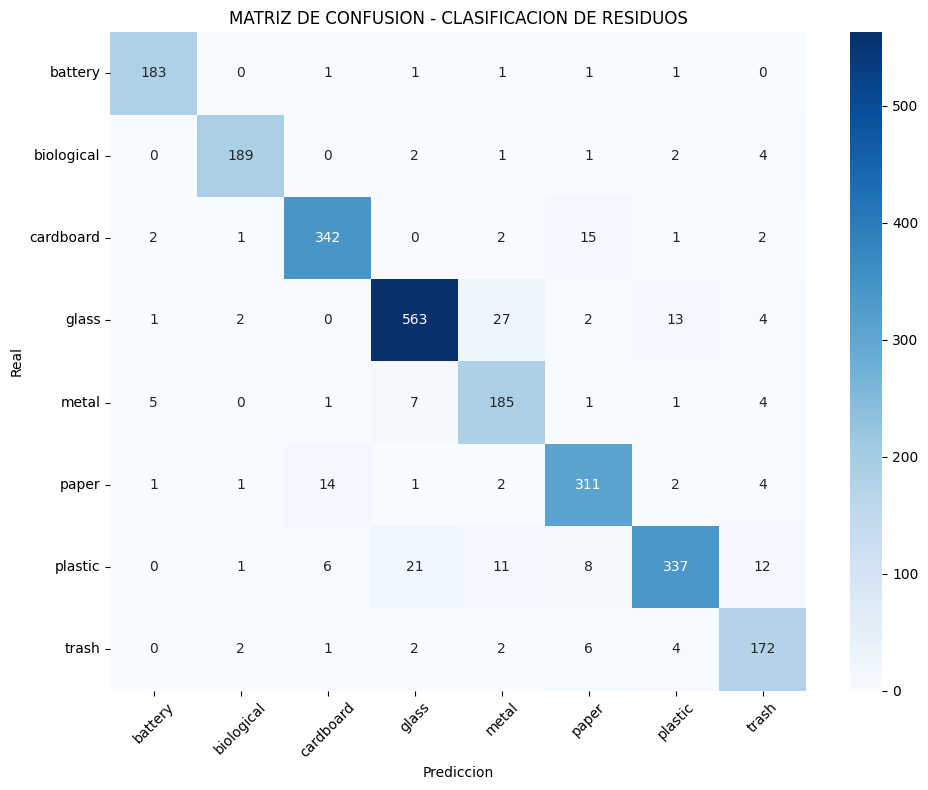

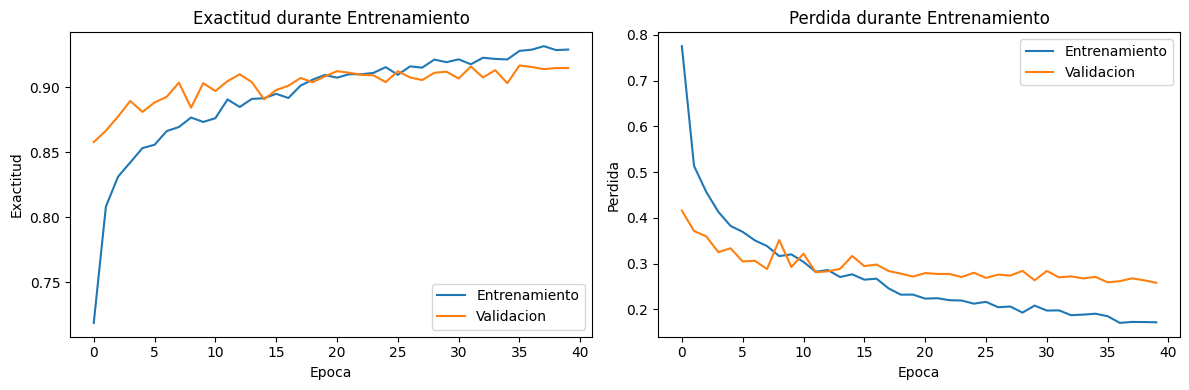

In [ ]:
# --- VISUALIZACION DE RESULTADOS ---
print("\n=== VISUALIZACION DE RESULTADOS ===")

# 1. Matriz de confusion
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('MATRIZ DE CONFUSION - CLASIFICACION DE RESIDUOS')
plt.xlabel('Prediccion')
plt.ylabel('Real')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Curvas de aprendizaje
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validacion')
plt.title('Exactitud durante Entrenamiento')
plt.xlabel('Epoca')
plt.ylabel('Exactitud')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validacion')
plt.title('Perdida durante Entrenamiento')
plt.xlabel('Epoca')
plt.ylabel('Perdida')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# --- METRICAS FINALES DEL SISTEMA ---
print("\n=== METRICAS FINALES DEL SISTEMA ===")

# Calcular metricas adicionales
from sklearn.metrics import f1_score

f1 = f1_score(y_true, y_pred, average='weighted')
accuracy = val_accuracy

print(f"Exactitud del sistema: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Puntuacion F1: {f1:.4f}")
print(f"Total de muestras validadas: {len(y_true)}")
print(f"Clasificaciones correctas: {np.sum(y_true == y_pred)}")

# Guardar metricas en archivo
metricas = {
    'exactitud': accuracy,
    'perdida': val_loss,
    'precision': val_precision,
    'recall': val_recall,
    'f1_score': f1
}

with open('modelos_upa/metricas_finales.txt', 'w') as f:
    f.write("METRICAS DEL SISTEMA DE CLASIFICACION DE RESIDUOS UPAO\n")
    f.write("====================================================\n")
    for key, value in metricas.items():
        f.write(f"{key}: {value:.4f}\n")


=== METRICAS FINALES DEL SISTEMA ===
Exactitud del sistema: 0.9168 (91.68%)
Puntuacion F1: 0.9171
Total de muestras validadas: 2489
Clasificaciones correctas: 2282


In [ ]:
# --- GUARDADO FINAL Y IMPLEMENTACION ---
print("\n=== IMPLEMENTACION DEL MODELO ===")

# Guardar modelo final para produccion
best_model.save('modelos_upa/modelo_final_residuos_upao.h5')
print("Modelo final guardado: modelos_upa/modelo_final_residuos_upao.h5")

# Resumen de implementacion
print("\nRESUMEN DE IMPLEMENTACION:")
print("Sistema de clasificacion de residuos desarrollado exitosamente")
print("Caracteristicas del sistema:")
print("- Arquitectura: MobileNetV2 con Transfer Learning")
print("- Entrenamiento distribuido con GPU")
print("- 8 categorias de residuos clasificables")
print("- Balanceo automatico de clases")
print("- Metricas de evaluacion completas")
print("- Modelo listo para implementacion en UPAO")

print("\n=== PROYECTO COMPLETADO ===")


=== IMPLEMENTACION DEL MODELO ===
Modelo final guardado: modelos_upa/modelo_final_residuos_upao.h5

RESUMEN DE IMPLEMENTACION:
Sistema de clasificacion de residuos desarrollado exitosamente
Caracteristicas del sistema:
- Arquitectura: MobileNetV2 con Transfer Learning
- Entrenamiento distribuido con GPU
- 8 categorias de residuos clasificables
- Balanceo automatico de clases
- Metricas de evaluacion completas
- Modelo listo para implementacion en UPAO

=== PROYECTO COMPLETADO ===


In [ ]:
# =============================================================================
# PRUEBA CON IMÁGENES DE TU COMPUTADORA
# =============================================================================

print("=== PRUEBA CON TUS PROPIAS IMÁGENES ===")

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files
import io
from PIL import Image

# Cargar el modelo entrenado
model = tf.keras.models.load_model('modelos_upa/mejor_modelo_residuos.h5')

# Nombres de las clases
class_names = ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

print("Modelo cargado exitosamente")
print("Clases que puede reconocer:", class_names)

=== PRUEBA CON TUS PROPIAS IMÁGENES ===


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'modelos_upa/mejor_modelo_residuos.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)


1. SUBE UNA IMAGEN DE RESIDUO DESDE TU COMPUTADORA


Saving glass_1.jpg to glass_1 (1).jpg
✅ Imagen subida: glass_1 (1).jpg


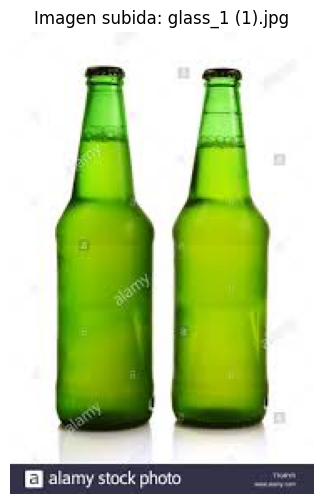

In [ ]:
# --- SUBIR IMAGEN DESDE TU COMPUTADORA ---
print("\n1. SUBE UNA IMAGEN DE RESIDUO DESDE TU COMPUTADORA")

# Esto abrirá una ventana para seleccionar archivo
uploaded = files.upload()

# Verificar que se subió algo
if not uploaded:
    print("❌ No se subió ninguna imagen")
else:
    # Obtener el nombre del primer archivo subido
    image_name = list(uploaded.keys())[0]
    print(f"✅ Imagen subida: {image_name}")

    # Mostrar la imagen subida
    image_data = uploaded[image_name]
    img = Image.open(io.BytesIO(image_data))

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Imagen subida: {image_name}")
    plt.axis('off')
    plt.show()

In [ ]:
# --- PROCESAR Y CLASIFICAR LA IMAGEN ---
print("\n2. CLASIFICANDO LA IMAGEN...")

if uploaded:
    # Preprocesar la imagen para el modelo
    def preparar_imagen(image_data, target_size=(224, 224)):
        # Abrir imagen
        img = Image.open(io.BytesIO(image_data))
        # Redimensionar
        img = img.resize(target_size)
        # Convertir a array
        img_array = image.img_to_array(img)
        # Normalizar (igual que en entrenamiento)
        img_array = img_array / 255.0
        # Añadir dimensión del batch
        img_array = np.expand_dims(img_array, axis=0)
        return img_array, img

    # Preparar imagen
    img_array, img_original = preparar_imagen(image_data)

    # Hacer predicción
    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])
    predicted_label = class_names[predicted_class]

    print("✅ PREDICCIÓN COMPLETADA")
    print(f"🎯 El modelo clasifica esta imagen como: {predicted_label}")
    print(f"📊 Nivel de confianza: {confidence:.2%}")


2. CLASIFICANDO LA IMAGEN...


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
✅ PREDICCIÓN COMPLETADA
🎯 El modelo clasifica esta imagen como: glass
📊 Nivel de confianza: 100.00%


In [ ]:
# --- MOSTRAR RESULTADO DETALLADO ---
print("\n3. RESULTADO DETALLADO")

if uploaded:
    # Crear visualización completa
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Mostrar imagen original
    ax1.imshow(img_original)
    ax1.set_title(f'IMAGEN ORIGINAL\nClasificación: {predicted_label}\nConfianza: {confidence:.2%}')
    ax1.axis('off')

    # Mostrar gráfico de probabilidades
    probabilities = predictions[0]
    y_pos = np.arange(len(class_names))
    bars = ax2.barh(y_pos, probabilities)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(class_names)
    ax2.set_xlabel('Probabilidad')
    ax2.set_title('PROBABILIDADES POR CLASE')

    # Resaltar la predicción más alta
    bars[predicted_class].set_color('red')

    plt.tight_layout()
    plt.show()


3. RESULTADO DETALLADO


NameError: name 'uploaded' is not defined

In [ ]:
# --- INTERPRETACIÓN DEL RESULTADO ---
print("\n4. INTERPRETACIÓN:")

if uploaded:
    print(f"🔍 RESULTADO: {predicted_label}")
    print(f"📊 CONFIANZA: {confidence:.2%}")

    if confidence > 0.8:
        print("✅ ALTA CONFIANZA - Muy probable que sea correcto")
    elif confidence > 0.6:
        print("🟡 CONFIANZA MEDIA - Podría ser correcto")
    else:
        print("🟠 BAJA CONFIANZA - El modelo no está seguro")

    # Mostrar las 3 mejores predicciones
    print("\n🏆 TOP 3 PREDICCIONES:")
    top_3_indices = np.argsort(predictions[0])[-3:][::-1]
    for i, idx in enumerate(top_3_indices):
        prob = predictions[0][idx]
        print(f"  {i+1}. {class_names[idx]}: {prob:.2%}")


4. INTERPRETACIÓN:
🔍 RESULTADO: metal
📊 CONFIANZA: 87.40%
✅ ALTA CONFIANZA - Muy probable que sea correcto

🏆 TOP 3 PREDICCIONES:
  1. metal: 87.40%
  2. battery: 12.16%
  3. glass: 0.37%


In [ ]:
# --- PROBAR CON MÁS IMÁGENES ---
print("\n5. ¿QUIERES PROBAR CON MÁS IMÁGENES?")

def probar_otra_imagen():
    print("\n¿Quieres probar con otra imagen?")
    print("Ejecuta otra vez la celda de 'SUBIR IMAGEN' o")
    print("vuelve a ejecutar todo desde el principio")

probar_otra_imagen()


5. ¿QUIERES PROBAR CON MÁS IMÁGENES?

¿Quieres probar con otra imagen?
Ejecuta otra vez la celda de 'SUBIR IMAGEN' o
vuelve a ejecutar todo desde el principio


In [ ]:
# --- EJECUTAR ESTO ANTES DE CERRAR COLAB ---
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
import os
import json

# 1. Guardar modelo en Google Drive
drive_path = '/content/drive/MyDrive/proyecto_upao_residuos'
os.makedirs(drive_path, exist_ok=True)

# Guardar modelo
best_model.save(f'{drive_path}/modelo_residuos.h5')

# 2. Guardar información de clases
class_info = {
    'class_names': ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash'],
    'class_indices': train_generator.class_indices
}
with open(f'{drive_path}/clases.json', 'w') as f:
    json.dump(class_info, f)

# 3. Guardar dataset (opcional pero recomendado)
import shutil
shutil.make_archive('/content/dataset_residuos', 'zip', 'garbage/garbage-dataset')
shutil.copy('/content/dataset_residuos.zip', f'{drive_path}/dataset_residuos.zip')

print("✅ TODO guardado en Google Drive")
print("📁 Ruta:", drive_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ TODO guardado en Google Drive
📁 Ruta: /content/drive/MyDrive/proyecto_upao_residuos


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== DEMOSTRACIÓN PROYECTO CLASIFICACIÓN DE RESIDUOS UPAO ===


✅ Modelo cargado exitosamente
🎯 Clases: ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

📸 SUBE UNA IMAGEN DE RESIDUO PARA CLASIFICAR:


Saving Batteries.jpg to Batteries.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


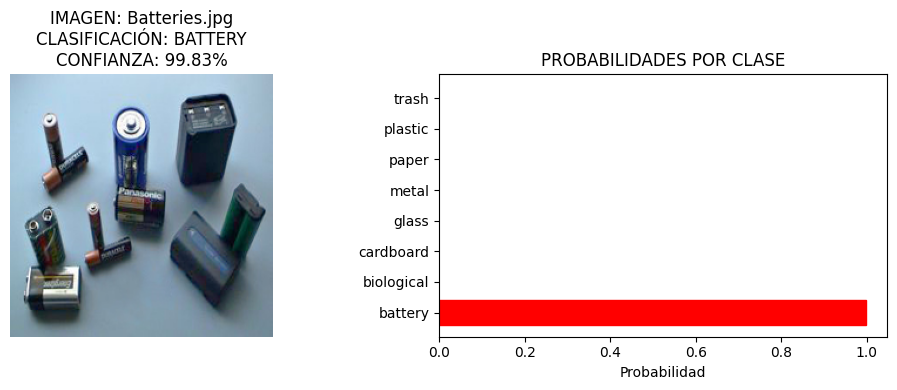


🎯 RESULTADO: battery (99.83%)
¡Sistema funcionando correctamente!


In [ ]:
# --- CÓDIGO PARA EJECUTAR EN LA UNIVERSIDAD ---

# 1. Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Importar librerías
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files
import json
from PIL import Image
import io

print("=== DEMOSTRACIÓN PROYECTO CLASIFICACIÓN DE RESIDUOS UPAO ===")

# 3. Cargar modelo guardado
model_path = '/content/drive/MyDrive/proyecto_upao_residuos/modelo_residuos.h5'
model = tf.keras.models.load_model(model_path)

# 4. Cargar información de clases
with open('/content/drive/MyDrive/proyecto_upao_residuos/clases.json', 'r') as f:
    class_info = json.load(f)

class_names = class_info['class_names']
print("✅ Modelo cargado exitosamente")
print(f"🎯 Clases: {class_names}")

# 5. Función para probar con imágenes
def demostrar_clasificacion():
    print("\n📸 SUBE UNA IMAGEN DE RESIDUO PARA CLASIFICAR:")

    # Subir imagen
    uploaded = files.upload()

    if uploaded:
        image_name = list(uploaded.keys())[0]
        image_data = uploaded[image_name]

        # Procesar imagen
        img = Image.open(io.BytesIO(image_data))
        img = img.resize((224, 224))
        img_array = image.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        # Predecir
        predictions = model.predict(img_array)
        predicted_class = np.argmax(predictions[0])
        confidence = np.max(predictions[0])
        predicted_label = class_names[predicted_class]

        # Mostrar resultados
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(img)
        plt.title(f'IMAGEN: {image_name}\nCLASIFICACIÓN: {predicted_label.upper()}\nCONFIANZA: {confidence:.2%}')
        plt.axis('off')

        plt.subplot(1, 2, 2)
        probabilities = predictions[0]
        bars = plt.barh(class_names, probabilities)
        bars[predicted_class].set_color('red')
        plt.xlabel('Probabilidad')
        plt.title('PROBABILIDADES POR CLASE')

        plt.tight_layout()
        plt.show()

        print(f"\n🎯 RESULTADO: {predicted_label} ({confidence:.2%})")
        print("¡Sistema funcionando correctamente!")

# 6. Ejecutar demostración
demostrar_clasificacion()

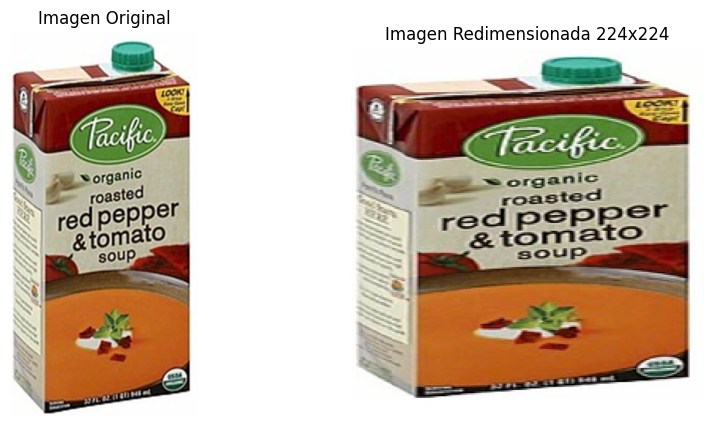

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Elegir una categoría aleatoria
categorias = sorted(os.listdir(dataset_path))
categoria = random.choice(categorias)

# Elegir imagen aleatoria
categoria_path = os.path.join(dataset_path, categoria)
img_name = random.choice(os.listdir(categoria_path))
img_path = os.path.join(categoria_path, img_name)

# Cargar imagen original
img_original = image.load_img(img_path)

# Cargar imagen redimensionada
img_resized = image.load_img(img_path, target_size=(224,224))

# Mostrar ambas
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_original)
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_resized)
plt.title("Imagen Redimensionada 224x224")
plt.axis("off")

plt.show()

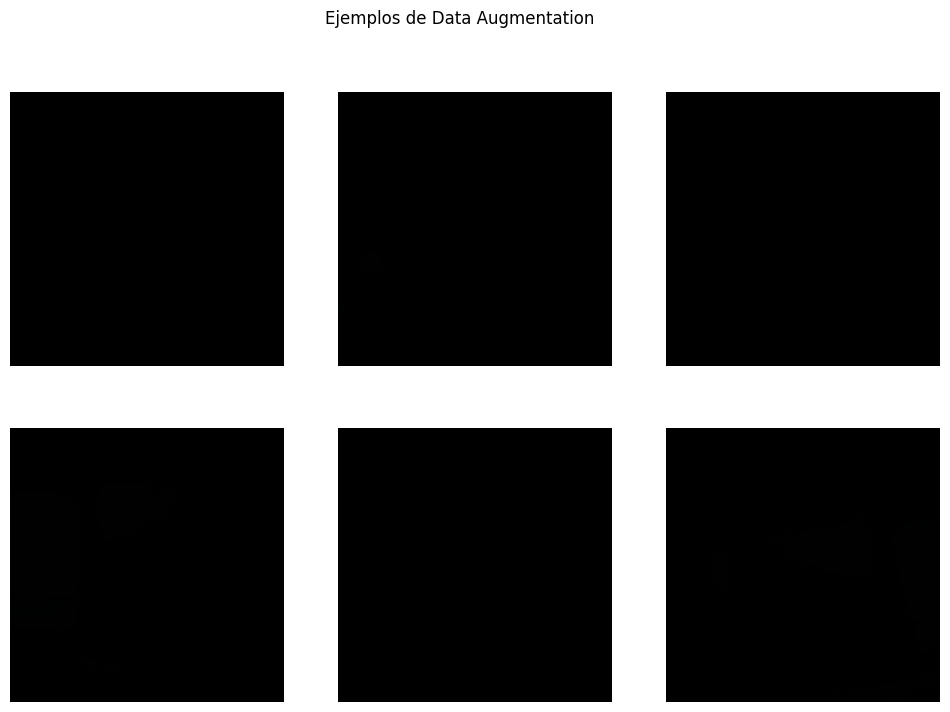

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Elegir imagen aleatoria
categorias = sorted(os.listdir(dataset_path))
categoria = random.choice(categorias)

categoria_path = os.path.join(dataset_path, categoria)
img_name = random.choice(os.listdir(categoria_path))
img_path = os.path.join(categoria_path, img_name)

# Cargar imagen
img = image.load_img(img_path, target_size=(224,224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)

# Generar imágenes aumentadas
aug_iter = train_datagen.flow(x, batch_size=1)

# Mostrar resultados
plt.figure(figsize=(12,8))

for i in range(6):
    plt.subplot(2,3,i+1)

    batch = next(aug_iter)
    aug_img = batch[0].astype('uint8')

    plt.imshow(aug_img)
    plt.axis("off")

plt.suptitle("Ejemplos de Data Augmentation")
plt.show()

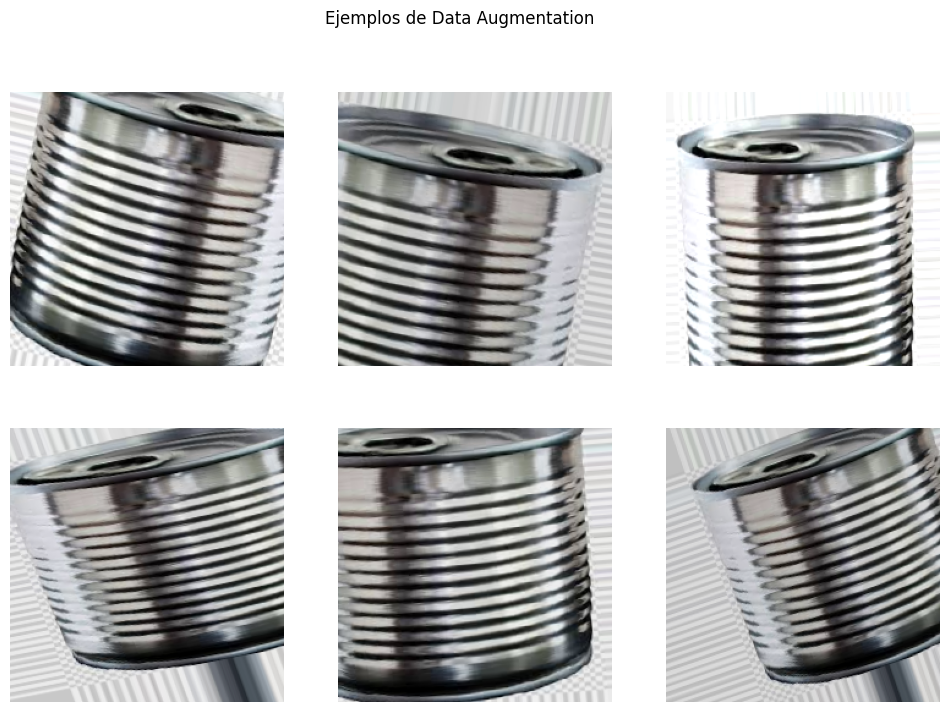

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Elegir imagen aleatoria
categorias = sorted(os.listdir(dataset_path))
categoria = random.choice(categorias)

categoria_path = os.path.join(dataset_path, categoria)
img_name = random.choice(os.listdir(categoria_path))
img_path = os.path.join(categoria_path, img_name)

# Cargar imagen
img = image.load_img(img_path, target_size=(224,224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)

# Generar imágenes aumentadas
aug_iter = train_datagen.flow(x, batch_size=1)

# Mostrar resultados
plt.figure(figsize=(12,8))

for i in range(6):
    plt.subplot(2,3,i+1)

    batch = next(aug_iter)

    # CORRECCIÓN
    aug_img = (batch[0] * 255).astype('uint8')

    plt.imshow(aug_img)
    plt.axis("off")

plt.suptitle("Ejemplos de Data Augmentation")
plt.show()

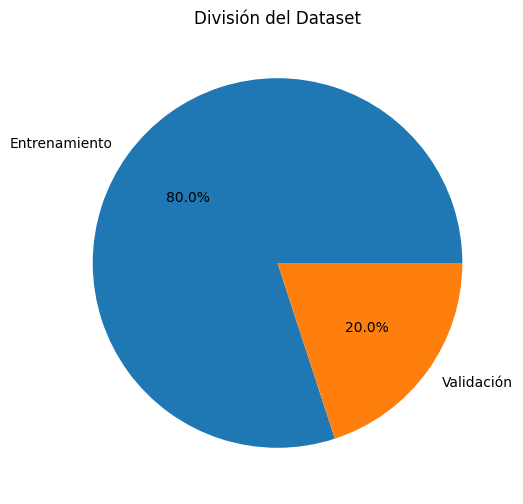

In [ ]:
import matplotlib.pyplot as plt

# Datos
labels = ['Entrenamiento', 'Validación']
sizes = [9969, 2489]

# Crear gráfico
plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%')

plt.title('División del Dataset')

# Guardar imagen
plt.savefig("division_dataset.png", bbox_inches='tight')

plt.show()

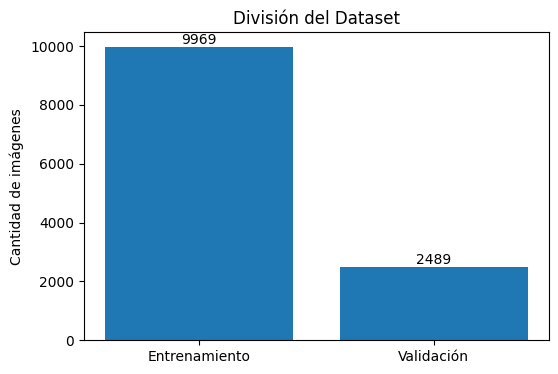

In [ ]:
import matplotlib.pyplot as plt

labels = ['Entrenamiento', 'Validación']
values = [9969, 2489]

plt.figure(figsize=(6,4))
plt.bar(labels, values)

plt.ylabel('Cantidad de imágenes')
plt.title('División del Dataset')

# Mostrar números encima
for i, v in enumerate(values):
    plt.text(i, v + 100, str(v), ha='center')

plt.savefig("division_dataset_barras.png", bbox_inches='tight')

plt.show()

MODELO BASE

In [ ]:
!pip install scikit-image

In [ ]:
import os
import cv2
import numpy as np
from tqdm import tqdm

from skimage.feature import hog

from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# =========================
# CONFIGURACIÓN
# =========================

img_size = (128, 128)

X = []
y = []

categorias = sorted(os.listdir(dataset_path))

print("Categorías:", categorias)

# =========================
# CARGA DE IMÁGENES
# =========================

for categoria in categorias:

    categoria_path = os.path.join(dataset_path, categoria)

    if not os.path.isdir(categoria_path):
        continue

    for img_name in tqdm(os.listdir(categoria_path)):

        img_path = os.path.join(categoria_path, img_name)

        try:
            # Leer imagen en escala de grises
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

            # Redimensionar
            img = cv2.resize(img, img_size)

            # Extraer características HOG
            features = hog(
                img,
                orientations=9,
                pixels_per_cell=(8,8),
                cells_per_block=(2,2),
                block_norm='L2-Hys'
            )

            X.append(features)
            y.append(categoria)

        except:
            pass

# Convertir a numpy
X = np.array(X)
y = np.array(y)

print("Dataset cargado:", X.shape)

# =========================
# DIVISIÓN
# =========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =========================
# MODELO SVM
# =========================

svm_model = LinearSVC()

print("Entrenando SVM...")
svm_model.fit(X_train, y_train)

# =========================
# PREDICCIONES
# =========================

y_pred = svm_model.predict(X_test)

# =========================
# MÉTRICAS
# =========================

accuracy = accuracy_score(y_test, y_pred)

print(f"\nAccuracy Baseline HOG + SVM: {accuracy:.4f}")

print("\nReporte de Clasificación:\n")
print(classification_report(y_test, y_pred))

Categorías: ['battery', 'biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


100%|██████████| 947/947 [00:08<00:00, 118.09it/s]


Dataset cargado: (12458, 8100)
Entrenando SVM...

Accuracy Baseline HOG + SVM: 0.4270

Reporte de Clasificación:

              precision    recall  f1-score   support

     battery       0.47      0.39      0.43       189
  biological       0.29      0.23      0.26       200
   cardboard       0.47      0.45      0.46       365
       glass       0.51      0.52      0.52       612
       metal       0.26      0.27      0.27       204
       paper       0.45      0.51      0.48       336
     plastic       0.45      0.48      0.46       397
       trash       0.24      0.23      0.24       189

    accuracy                           0.43      2492
   macro avg       0.39      0.39      0.39      2492
weighted avg       0.42      0.43      0.42      2492



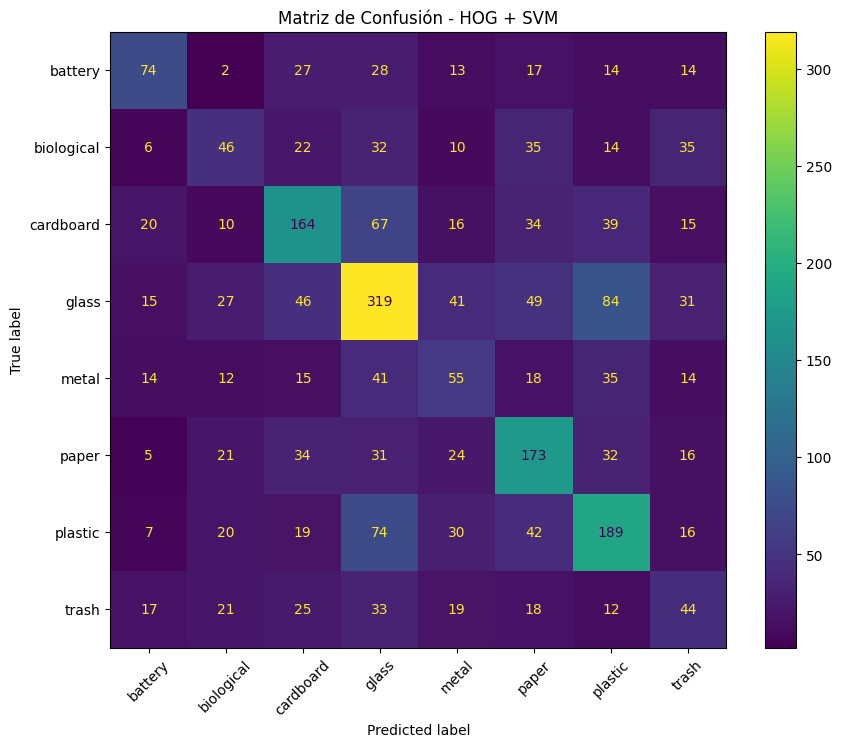

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Crear matriz de confusión
cm = confusion_matrix(y_test, y_pred)

# Tamaño de figura
fig, ax = plt.subplots(figsize=(10,8))

# Mostrar matriz
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)

disp.plot(ax=ax, xticks_rotation=45)

# Título
plt.title("Matriz de Confusión - HOG + SVM")

# Guardar imagen
plt.savefig("matriz_confusion_svm.png", bbox_inches='tight')

# Mostrar
plt.show()

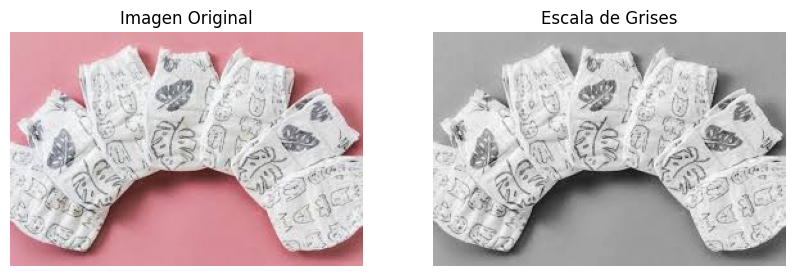

In [ ]:
import cv2
import matplotlib.pyplot as plt
import random
import os

# Elegir imagen aleatoria
categorias = sorted(os.listdir(dataset_path))
categoria = random.choice(categorias)

categoria_path = os.path.join(dataset_path, categoria)
img_name = random.choice(os.listdir(categoria_path))
img_path = os.path.join(categoria_path, img_name)

# Leer imagen
img_color = cv2.imread(img_path)

# Convertir BGR a RGB
img_color_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

# Escala de grises
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# Mostrar
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_color_rgb)
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_gray, cmap='gray')
plt.title("Escala de Grises")
plt.axis("off")

plt.savefig("rgb_vs_gray.png", bbox_inches='tight')

plt.show()

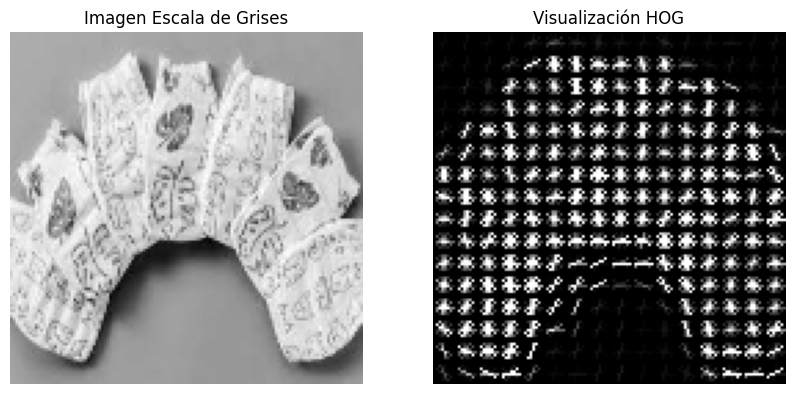

In [ ]:
from skimage.feature import hog
from skimage import exposure

# Redimensionar imagen
img_resized = cv2.resize(img_gray, (128,128))

# Extraer HOG + visualización
features, hog_image = hog(
    img_resized,
    orientations=9,
    pixels_per_cell=(8,8),
    cells_per_block=(2,2),
    block_norm='L2-Hys',
    visualize=True
)

# Mejorar visualización
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0,10))

# Mostrar
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_resized, cmap='gray')
plt.title("Imagen Escala de Grises")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(hog_image_rescaled, cmap='gray')
plt.title("Visualización HOG")
plt.axis("off")

plt.savefig("hog_visualizacion.png", bbox_inches='tight')

plt.show()